# Project 2

Welcome to the second NLP1 project. The goal of the second tutorial was to get you familiar with using pre-trained embeddings and moving towards a compositional encoder for text classification.

Given the skills you have developed in the last week, you will now be applying them within the dataset and task you have chosen during Project 1. You will be applying hands-on the experiments you have already explored in the Tutorial 2, and taking a deeper dive: extending your experiments, trying different set ups, possibly considering different evaluation techniques and errors analyses, and tackling your own research questions. 


The week after the deadline, your TA will perform a short oral assessment of the skills and knowledge you acquired (make sure to check the official schedule for this), probing you to answer questions about what you learnt, about what you did and about why you did the things you did (as opposed to some reasonable alternatives) as well as pros and cons of your method, and so on. 

# Get to work!

1. Find a word embedding model that is appropriate for your dataset. Think about the language, the kind of text you are working with. Find evidence that your choice is a good one: 
    * Can you tokenize your texts in a way coherent with the definition of a token in the embedding model?
    * Does the model's vocabulary give enough coverage to the words in your texts? etc.
2. Explore what your chosen word embedding model captures. Some things you might consider: 
    * Is it good at representing interesting similarities (re to your choice of task)? J
    * Have you found task-specific evidence that it's better than some other reasonable alternative?
    * Do you know about limitations of this model?
    * Any limitations that you find particularly troubling for your task? 
3. Experiment with the embed-and-pool approach.  
    * What design choices have meaningful impact in classification performance (eg, embedding size, architecture design, optimisation parameters), if any?
    * Is this better than what you could achieve last week? In other words, did pretrained embeddings add to your design?
4. Experiment with a recurrent encoder (GRU or LSTM). 
    * What design choices have meaningful impact in classification performance, if any?
    * Did you investigate the impact of data size, embedding parameters (trained or not, fixed or trainable, etc)?
    * Did you struggle with over-fitting?
    * How far can this approach go? Are you able to improve meaningfully on embed-and-pool?
5. We make decisions under uncertainty all the time, are you gathering enough information to substantiate your choices? Various things can lead to small differences in results, and these differences are not always consistent. Here are some things to think about:
    * How did you structure you hyperparameter search?
    * Are you keeping an eye on experimental variance?
6. Experiment with error analysis and try to discover what characteristics of input texts are predictive of performance differences across major design choices. 
    * What analysis features did you come up with?
    * Which ones did you manage to test and how did that go?
    * What would you prioritise in the future in order to improve your systems?

Be mindful that you will be using your experiments to write up your final blog, so make sure your code is clean and neat!

If you are unsure about anything, ask your TA! They are always happy to help you! Happy coding! :)

# Tips

## Pretrained embedding models

We will post a list with some options for you. 

## Features for analysis

Features that you can interpret as an aspect of _complexity_ in light of your task's goals.

- length
- presence of rare/common words, including unknown words
- syntactic features (like parts-of-speech, syntactic complexity, syntactic voice, presence of negation, etc.)
- semantic features (eg, the average similarity of the text to training documents or some curated set of training documents, presence of words in certain semantic classes, etc.)
- task-specific features (eg, 
- model-specific features (eg, predicted label, probability assigned to predicted label, number of parameters or layers or some other model descriptor)

In [1]:
from pathlib import Path

results_folder = Path("./results")
results_folder.mkdir(parents=True, exist_ok=True)

from datasets import load_dataset

snli = load_dataset("stanfordnlp/snli")
print(snli)

import re
from sklearn.model_selection import train_test_split
from collections import defaultdict

WORKING_SET_SIZE = 40_000
SUBSAMPLE_SEED = 0  # fixed for reproducibility 

# Drop the -1 examples keep (premise, hypothesis, label).
# train_pairs_all = [
#     ((ex["premise"], ex["hypothesis"]), ex["label"])
#     for ex in snli["train"]
#     if ex["label"] != -1
# ]


url_pattern = re.compile(r"https?://|www\.", re.IGNORECASE)


pair_labels = defaultdict(set)
for ex in snli["train"]:
    if ex["label"] != -1:
        pair_labels[(ex["premise"], ex["hypothesis"])].add(ex["label"])

print(f'Before: {len(snli["train"])}')
train_pairs_all = []
for ex in snli["train"]:
    if ex["label"] == -1:
        continue
    if ex["premise"] == ex["hypothesis"] and ex['label'] != 0:
        continue
    if len(pair_labels[(ex["premise"], ex["hypothesis"])]) > 1:
        continue
    if len(ex["hypothesis"].split()) <= 1:
        continue
    if url_pattern.search(ex["premise"]) or url_pattern.search(ex["hypothesis"]):
        continue
    train_pairs_all.append(((ex["premise"], ex["hypothesis"]), ex["label"]))
print(f'After: {len(train_pairs_all)}')
print(f'Differece: {len(snli["train"]) - len(train_pairs_all)}')


# Stratified subsample to the working-set size (preserves the balanced label dist).
X = [ph for ph, _ in train_pairs_all]
y = [lab for _, lab in train_pairs_all]

X_work, _, y_work, _ = train_test_split(
    X, y,
    train_size=WORKING_SET_SIZE,
    stratify=y,
    random_state=SUBSAMPLE_SEED,
)

# Reassemble into the ((premise, hypothesis), label) list we'll feed to CV.
working_set = list(zip(X_work, y_work))

#check: size + label distribution preserved.
from collections import Counter
print(f"Working set size: {len(working_set)}")
print("Label dist (0/1/2):", dict(sorted(Counter(y_work).items())))

README.md:   0%|          | 0.00/16.0k [00:00<?, ?B/s]

DatasetDict({
    test: Dataset({
        features: ['premise', 'hypothesis', 'label'],
        num_rows: 10000
    })
    validation: Dataset({
        features: ['premise', 'hypothesis', 'label'],
        num_rows: 10000
    })
    train: Dataset({
        features: ['premise', 'hypothesis', 'label'],
        num_rows: 550152
    })
})
Before: 550152
After: 549173
Differece: 979
Working set size: 40000
Label dist (0/1/2): {0: 13354, 1: 13307, 2: 13339}


In [3]:
import torch
from transformers import AutoTokenizer, AutoModel

bert_name = "google-bert/bert-base-uncased"
bert_tokenizer = AutoTokenizer.from_pretrained(bert_name)
bert_model = AutoModel.from_pretrained(bert_name)

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
bert_model.to(device)

BATCH_SIZE = 64
first_sentences = [example[0] for example in X_work]
second_sentences = [example[1] for example in X_work]

labels = torch.tensor(y_work, dtype=torch.int64)

# Embed everything
token_embeddings = []
with torch.no_grad():
    for i in range(0, len(first_sentences), BATCH_SIZE):
        encoding = bert_tokenizer(
            first_sentences[i:i + BATCH_SIZE],
            second_sentences[i:i + BATCH_SIZE],
            padding=True,
            truncation=True,
            return_tensors="pt",
        )
        encoding = encoding.to(device)
        out = bert_model(**encoding)
        lengths = encoding["attention_mask"].sum(-1)
        for j in range(len(lengths)):
            # drop the [PAD] positions, float16 halves the memory
            token_embeddings.append(out.last_hidden_state[j, :lengths[j]].half().cpu())

torch.save(token_embeddings, results_folder / "bert_token_embeddings.pt")


W1119 19:10:59.133000 45932 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [17]:
from torch.nn.utils.rnn import pack_padded_sequence
from torch import nn


class LSTMEncoder(nn.Module):
    def __init__(self, hidden_size, embedding_dim, padding_idx=0, freeze_embeddings=True, word_dropout=0.):
        """
        hidden_size: size of the recurrent state
        embedding_matrix: word vectors
        padding_idx: id of the pad token
        freeze_embeddings: treat embeddings as frozen
        """
        super().__init__()

        self.hidden_size = hidden_size
        self.word_dropout = word_dropout
        
        # LSTM
        self.lstm = nn.LSTM(
            input_size=embedding_dim, 
            hidden_size=hidden_size,
            num_layers=1, # this could be turned into an argument 
            batch_first=True  # important, in NLP we treat the first axis of the tensor as the batch dimension, and the second as the sequence dimension
        )

    @property
    def enc_dim(self):
        return self.hidden_size

    def forward(self, x, mask):
        """
        Encode each sequence in the batch into a single H-dimensional vector.
        
        x: a batch of sequences of token ids
        """
        if self.training and self.word_dropout > 0:
            # Independently zero each non-padding token with probability word_dropout.
            # [..., max_seq_len]
            drop_mask = (
                torch.rand(mask.shape, device=x.device) < self.word_dropout # at a certain pre-specified rate
            ) & mask
            # we 0-out the embedding of a valid (not pad) position
            x = x.masked_fill(drop_mask.unsqueeze(-1), 0.0)
                
        # [..., max_seq_len] this is necessary for packing
        lengths = torch.sum(mask, dim=-1)
        # for efficiency, we let torch do the for loop, and for that we need to 'pack' our sentences
        # using a torch helper
        packed = pack_padded_sequence(x, lengths.cpu(), batch_first=True, enforce_sorted=False) # sorting leads to even more efficient processing, but it is cumbersome and we skip it
        output, (hidden, cell) = self.lstm(packed)
        final_hidden = hidden[-1]
        return final_hidden        

In [18]:
class SoftmaxRegressor(nn.Module):
    """
    This is a softmax regressor, 
     it works with encoded text h(x) as input.
    The map from h(x) to outputs uses an MLP.

    One important detail: for numerical stability the output is not softmax-activitate, 
     rather, it is logsoftmax-activated. This means the outputs are log prob masses, not prob masses.
    """
    def __init__(self, hidden_size1, hidden_size2, num_classes, encoder: nn.Module):
        """
        hidden_size1: size of first hidden layer (in the output transformation)
        hidden_size2: size of second hidden layer
        num_classes: number of possible classes
        encoder: an nn.Module that maps each x to a single vector of size encoder.enc_dim
        """
        super().__init__()
        self.encoder = encoder      
        self.num_classes = num_classes
        self.mlp = nn.Sequential(
            nn.Linear(encoder.enc_dim, hidden_size1),
            nn.Tanh(),
            nn.Linear(hidden_size1, hidden_size2),
            nn.Tanh(),
            nn.Linear(hidden_size2, num_classes),
        )

    def forward(self, x, mask):  
        """
        for each sequence in the batch, encode it, then map the result to log probs for the possible classes
        return a tensor with shape (batch_size, num_classes) of log probs
        """
        encoded_x = self.encoder(x, mask)
        out = self.mlp(encoded_x)
        return torch.nn.functional.log_softmax(out, dim=1)

In [19]:
import torch
from torch.nn.utils.rnn import pad_sequence

def collate(batch):
    # batch = (embedding [len_k, 768], label) pairs
    seqs, ys = zip(*batch)
    lengths = torch.tensor([len(s) for s in seqs])  # [B, lens]
    x = pad_sequence(seqs, batch_first=True).float()  # [B, longest_len, 768], zeros at the end
    mask = torch.arange(x.shape[1])[None, :] < lengths[:, None]  # [B, longest_len], True = real token
    return x, mask, torch.tensor(ys)



In [22]:
import sys
import json
import numpy as np
from pathlib import Path
from torch.utils.data import DataLoader

sys.path.insert(0, str(Path.cwd().parent))
from part1.experiment import cross_validation_split

CV_SEEDS = [0, 3, 5]
NUM_FOLDS = 5
QUICK = False   # True: only seed 0 / fold 0, to check everything works. False: all 15 runs.

enc_kwargs = {'hidden_size': 256, 'embedding_dim': 768, 'word_dropout': 0.1}
regressor_kwargs = {'hidden_size1': 256, 'hidden_size2': 256, 'num_classes': 3}
opt_kwargs = {'learning_rate': 1e-3, 'weight_decay': 1e-4, 'batch_size': 128, 'num_epochs': 10}


def training_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss, total_correct, total = 0., 0, 0
    for x, mask, y in loader:
        x, mask, y = x.to(device), mask.to(device), y.to(device)
        optimizer.zero_grad()
        logprobs = model(x, mask)
        loss = criterion(logprobs, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * y.size(0)
        total_correct += (logprobs.argmax(1) == y).sum().item()
        total += y.size(0)
    return {'loss': total_loss / total, 'accuracy': total_correct / total}


def evaluate(model, loader, criterion):
    model.eval()
    total_loss, total_correct, total = 0., 0, 0
    predictions = []
    with torch.no_grad():
        for x, mask, y in loader:
            x, mask, y = x.to(device), mask.to(device), y.to(device)
            logprobs = model(x, mask)
            loss = criterion(logprobs, y)
            total_loss += loss.item() * y.size(0)
            total_correct += (logprobs.argmax(1) == y).sum().item()
            total += y.size(0)
            predictions.extend(logprobs.argmax(1).tolist())
    return {'loss': total_loss / total, 'accuracy': total_correct / total, 'predictions': predictions}


def train(training_set, validation_set, seed, save_to):
    train_loader = DataLoader(training_set, batch_size=opt_kwargs['batch_size'], shuffle=True, collate_fn=collate)
    val_loader = DataLoader(validation_set, batch_size=opt_kwargs['batch_size'], shuffle=False, collate_fn=collate)

    torch.manual_seed(seed)   # same initial weights for the same seed
    model = SoftmaxRegressor(encoder=LSTMEncoder(**enc_kwargs), **regressor_kwargs).to(device)
    criterion = nn.NLLLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=opt_kwargs['learning_rate'], weight_decay=opt_kwargs['weight_decay'])

    metrics = []
    best_val_loss, best_epoch = float('inf'), 0
    for epoch in range(opt_kwargs['num_epochs']):
        train_metrics = training_one_epoch(model, train_loader, optimizer, criterion)
        val_metrics = evaluate(model, val_loader, criterion)
        metrics.append({'train_metrics': train_metrics, 'val_metrics': val_metrics})
        print(f"Epoch {epoch + 1:02d} | train loss {train_metrics['loss']:.4f} | train acc {train_metrics['accuracy']:.4f} | "
              f"val loss {val_metrics['loss']:.4f} | val acc {val_metrics['accuracy']:.4f}")

        # keep the model from the epoch with the lowest validation loss
        if val_metrics['loss'] <= best_val_loss:
            best_val_loss, best_epoch = val_metrics['loss'], epoch
            torch.save(model.state_dict(), f"{save_to}.pt")

    with open(f"{save_to}.json", 'w') as f:
        json.dump({'metrics': metrics, 'best_epoch': best_epoch,
                   'enc_kwargs': enc_kwargs, 'regressor_kwargs': regressor_kwargs, 'opt_kwargs': opt_kwargs}, f)
    return metrics, best_epoch


data = list(zip(token_embeddings, y_work))   # [(tensor [len, 768], label), ...]

runs = {}   # (seed, fold) -> {'metrics': ..., 'best_epoch': ...}
for seed in CV_SEEDS[:1] if QUICK else CV_SEEDS:
    folds = cross_validation_split(data, k=NUM_FOLDS, seed=seed)
    for fold_id, fold in folds.items():
        if QUICK and fold_id > 0:
            break
        print(f"\n=== seed {seed} | fold {fold_id} ===")
        folder = results_folder / 'bert_lstm' / f'seed-{seed}' / f'fold-{fold_id}'
        folder.mkdir(parents=True, exist_ok=True)
        metrics, best_epoch = train(fold['training'], fold['validation'], seed, save_to=folder / 'model')
        runs[(seed, fold_id)] = {'metrics': metrics, 'best_epoch': best_epoch}

accs = [r['metrics'][r['best_epoch']]['val_metrics']['accuracy'] for r in runs.values()]
print(f"\nval accuracy at best epoch: mean {np.mean(accs):.4f}, std {np.std(accs):.4f}, over {len(accs)} runs")


=== seed 0 | fold 0 ===
Epoch 01 | train loss 0.7642 | train acc 0.6620 | val loss 0.6249 | val acc 0.7465
Epoch 02 | train loss 0.5968 | train acc 0.7534 | val loss 0.5794 | val acc 0.7682
Epoch 03 | train loss 0.5327 | train acc 0.7861 | val loss 0.5466 | val acc 0.7799
Epoch 04 | train loss 0.4730 | train acc 0.8125 | val loss 0.5453 | val acc 0.7855
Epoch 05 | train loss 0.4167 | train acc 0.8382 | val loss 0.6135 | val acc 0.7660
Epoch 06 | train loss 0.3704 | train acc 0.8571 | val loss 0.5873 | val acc 0.7820
Epoch 07 | train loss 0.3166 | train acc 0.8808 | val loss 0.6102 | val acc 0.7791
Epoch 08 | train loss 0.2667 | train acc 0.9018 | val loss 0.6902 | val acc 0.7805
Epoch 09 | train loss 0.2277 | train acc 0.9157 | val loss 0.7224 | val acc 0.7741
Epoch 10 | train loss 0.1976 | train acc 0.9275 | val loss 0.7767 | val acc 0.7682

=== seed 0 | fold 1 ===
Epoch 01 | train loss 0.7609 | train acc 0.6667 | val loss 0.6166 | val acc 0.7451
Epoch 02 | train loss 0.6009 | train 

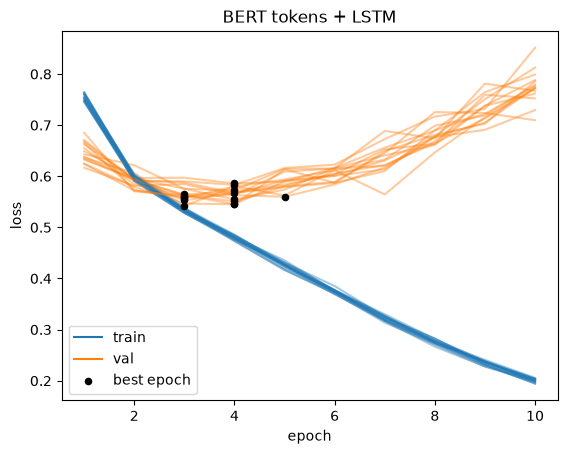

best epoch per run: [4, 5, 4, 4, 4, 3, 4, 4, 4, 4, 3, 3, 3, 3, 3]


In [23]:
import matplotlib.pyplot as plt

for (seed, fold_id), r in runs.items():
    epochs = range(1, len(r['metrics']) + 1)
    train_loss = [m['train_metrics']['loss'] for m in r['metrics']]
    val_loss = [m['val_metrics']['loss'] for m in r['metrics']]
    plt.plot(epochs, train_loss, color='tab:blue', alpha=0.4)
    plt.plot(epochs, val_loss, color='tab:orange', alpha=0.4)
    # best epoch = lowest val loss, this is the model that gets saved
    best = r['best_epoch']
    plt.scatter(best + 1, val_loss[best], color='black', zorder=3, s=20)

plt.plot([], color='tab:blue', label='train')
plt.plot([], color='tab:orange', label='val')
plt.scatter([], [], color='black', s=20, label='best epoch')
plt.xlabel('epoch'); plt.ylabel('loss'); plt.title('BERT tokens + LSTM'); plt.legend()
plt.show()

best_epochs = [r['best_epoch'] + 1 for r in runs.values()]
print('best epoch per run:', best_epochs)

In [24]:
from sklearn.model_selection import train_test_split

# one final model on the whole 40k, 10% held out only to pick the best epoch
final_train, final_val = train_test_split(data, test_size=0.1, stratify=y_work, random_state=0)
final_folder = results_folder / 'bert_lstm' / 'final'
final_folder.mkdir(parents=True, exist_ok=True)
final_metrics, final_best_epoch = train(final_train, final_val, seed=0, save_to=final_folder / 'model')

final_model = SoftmaxRegressor(encoder=LSTMEncoder(**enc_kwargs), **regressor_kwargs).to(device)
final_model.load_state_dict(torch.load(final_folder / 'model.pt', map_location=device))

Epoch 01 | train loss 0.7504 | train acc 0.6673 | val loss 0.6032 | val acc 0.7528
Epoch 02 | train loss 0.5886 | train acc 0.7617 | val loss 0.5554 | val acc 0.7780
Epoch 03 | train loss 0.5314 | train acc 0.7867 | val loss 0.5560 | val acc 0.7785
Epoch 04 | train loss 0.4762 | train acc 0.8109 | val loss 0.5386 | val acc 0.7927
Epoch 05 | train loss 0.4257 | train acc 0.8351 | val loss 0.5604 | val acc 0.7840
Epoch 06 | train loss 0.3752 | train acc 0.8587 | val loss 0.5756 | val acc 0.7880
Epoch 07 | train loss 0.3299 | train acc 0.8755 | val loss 0.6142 | val acc 0.7863
Epoch 08 | train loss 0.2837 | train acc 0.8944 | val loss 0.6758 | val acc 0.7798
Epoch 09 | train loss 0.2443 | train acc 0.9107 | val loss 0.6830 | val acc 0.7710
Epoch 10 | train loss 0.2071 | train acc 0.9247 | val loss 0.7218 | val acc 0.7792


<All keys matched successfully>

In [25]:
import urllib.request
import zipfile

bnli_folder = results_folder / 'breaking_nli'
bnli_folder.mkdir(parents=True, exist_ok=True)
bnli_path = bnli_folder / 'data' / 'dataset.jsonl'
if not bnli_path.exists():
    urllib.request.urlretrieve(
        'https://raw.githubusercontent.com/BIU-NLP/Breaking_NLI/master/breaking_nli_dataset.zip',
        bnli_folder / 'bn.zip')
    with zipfile.ZipFile(bnli_folder / 'bn.zip') as z:
        z.extractall(bnli_folder)

label_names = ['entailment', 'neutral', 'contradiction']   # same ids as SNLI: 0, 1, 2
bnli = []
with open(bnli_path, encoding='utf-8') as f:
    for line in f:
        d = json.loads(line)
        if d['gold_label'] in label_names:
            bnli.append(d)

print(len(bnli), 'pairs')
print(Counter(d['category'] for d in bnli).most_common())

8193 pairs
[('antonyms', 1147), ('synonyms', 894), ('cardinals', 759), ('nationalities', 755), ('drinks', 731), ('antonyms_wordnet', 706), ('colors', 699), ('ordinals', 663), ('countries', 613), ('rooms', 595), ('materials', 397), ('vegetables', 109), ('instruments', 65), ('planets', 60)]


In [26]:
def embed_pairs(premises, hypotheses, batch_size=64):
    result = []
    with torch.no_grad():
        for i in range(0, len(premises), batch_size):
            encoding = bert_tokenizer(
                premises[i:i + batch_size],
                hypotheses[i:i + batch_size],
                padding=True,
                truncation=True,
                return_tensors='pt',
            ).to(bert_model.device)
            out = bert_model(**encoding)
            lengths = encoding['attention_mask'].sum(-1)
            for j in range(len(lengths)):
                result.append(out.last_hidden_state[j, :lengths[j]].half().cpu())
    return result


bnli_embeddings = embed_pairs([d['sentence1'] for d in bnli], [d['sentence2'] for d in bnli])
bnli_labels = [label_names.index(d['gold_label']) for d in bnli]

bnli_loader = DataLoader(list(zip(bnli_embeddings, bnli_labels)), batch_size=128, shuffle=False, collate_fn=collate)
bnli_preds = evaluate(final_model, bnli_loader, nn.NLLLoss())['predictions']

In [28]:
import pandas as pd

groups = {
    'synonyms': ['synonyms'],
    'antonyms': ['antonyms', 'antonyms_wordnet'],
    'co-hyponyms': ['countries', 'nationalities', 'colors', 'materials', 'planets',
                    'drinks', 'vegetables', 'instruments', 'rooms'],
    'numbers': ['cardinals', 'ordinals'],
}
category_to_group = {c: g for g, cats in groups.items() for c in cats}

bnli_df = pd.DataFrame({
    'premise': [d['sentence1'] for d in bnli],
    'hypothesis': [d['sentence2'] for d in bnli],
    'category': [d['category'] for d in bnli],
    'gold': [d['gold_label'] for d in bnli],
    'pred': [label_names[p] for p in bnli_preds],
})
bnli_df['group'] = bnli_df['category'].map(category_to_group)
bnli_df['correct'] = bnli_df['gold'] == bnli_df['pred']

# 87% of the gold labels are contradiction, so overall accuracy alone says little
print(f"overall acc: {bnli_df['correct'].mean():.3f}   always-contradiction: {(bnli_df['gold'] == 'contradiction').mean():.3f}")
print('\npredicted labels:')
print(bnli_df['pred'].value_counts(normalize=True).round(3))
print('\nper group:')
print(bnli_df.groupby('group')['correct'].agg(['size', 'mean']).round(3))
print('\nper category:')
print(bnli_df.groupby('category')['correct'].agg(['size', 'mean']).sort_values('size', ascending=False).round(3))

bnli_df.to_csv(bnli_folder / 'bert_lstm_predictions.csv', index=False)

overall acc: 0.371   always-contradiction: 0.874

predicted labels:
pred
neutral          0.388
entailment       0.339
contradiction    0.273
Name: proportion, dtype: float64

per group:
             size   mean
group                   
antonyms     1853  0.119
co-hyponyms  4024  0.467
numbers      1422  0.145
synonyms      894  0.815

per category:
                  size   mean
category                     
antonyms          1147  0.053
synonyms           894  0.815
cardinals          759  0.179
nationalities      755  0.426
drinks             731  0.089
antonyms_wordnet   706  0.227
colors             699  0.727
ordinals           663  0.106
countries          613  0.514
rooms              595  0.679
materials          397  0.471
vegetables         109  0.239
instruments         65  0.538
planets             60  0.300
